In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 42

with open("../dados/metadados.json", encoding="utf-8") as f:
    meta = json.load(f)

colunas = meta["colunas_informativas"] + meta["colunas_ruido"]
treino = pd.read_csv("../dados/treino.csv")
teste = pd.read_csv("../dados/teste.csv")
X_train = treino[colunas]
X_test = teste[colunas]

indices = pd.read_csv("../resultados/amostra_indices.csv")["indice_teste"].values
X_amostra = X_test.loc[indices]

modelos = {
    "Random Forest": joblib.load("../resultados/modelos/random_forest.joblib"),
    "XGBoost": joblib.load("../resultados/modelos/xgboost.joblib"),
}


def ler(arquivo):
    return pd.read_csv(f"../resultados/{arquivo}", index_col=0).loc[indices, colunas].values


atribuicoes = {
    ("Random Forest", "SHAP"): ler("shap_rf.csv"),
    ("Random Forest", "LIME"): ler("lime_rf.csv"),
    ("XGBoost", "SHAP"): ler("shap_xgb.csv"),
    ("XGBoost", "LIME"): ler("lime_xgb.csv"),
}
print("Amostra:", X_amostra.shape)

Amostra: (100, 10)


In [2]:
idx_ruido = [colunas.index(c) for c in meta["colunas_ruido"]]
idx_info = [colunas.index(c) for c in meta["colunas_informativas"]]

linhas = []
for (nome, metodo), A in atribuicoes.items():
    imp = np.abs(A)
    frac_ruido = imp[:, idx_ruido].sum(axis=1) / imp.sum(axis=1)
    top7 = np.argsort(-imp, axis=1)[:, :7]
    precisao7 = np.isin(top7, idx_info).mean(axis=1)
    linhas.append(
        {
            "Modelo": nome,
            "Método": metodo,
            "Importância no ruído (%)": 100 * frac_ruido.mean(),
            "Precisão@7 (%)": 100 * precisao7.mean(),
        }
    )

tab_verdade = pd.DataFrame(linhas).set_index(["Modelo", "Método"]).round(2)
print(tab_verdade)
print("\nReferências: se a importância fosse distribuída ao acaso, o ruído receberia 30% e a Precisão@7 seria 70%.")
tab_verdade.to_csv("../resultados/fidelidade_verdade_fundamental.csv")

                      Importância no ruído (%)  Precisão@7 (%)
Modelo        Método                                          
Random Forest SHAP                        8.72           83.57
              LIME                        2.57           93.29
XGBoost       SHAP                        7.94           83.14
              LIME                        3.96           89.86

Referências: se a importância fosse distribuída ao acaso, o ruído receberia 30% e a Precisão@7 seria 70%.


       Modelo Método  k  Queda (explicação)  Queda (aleatório)  Ganho
Random Forest   SHAP  1              0.4616             0.0910 0.3705
Random Forest   SHAP  2              0.6133             0.1667 0.4466
Random Forest   SHAP  3              0.6964             0.2466 0.4498
Random Forest   LIME  1              0.2352             0.0910 0.1442
Random Forest   LIME  2              0.2766             0.1667 0.1099
Random Forest   LIME  3              0.2701             0.2466 0.0235
      XGBoost   SHAP  1              0.5876             0.0862 0.5014
      XGBoost   SHAP  2              0.8343             0.1747 0.6596
      XGBoost   SHAP  3              0.9071             0.2793 0.6279
      XGBoost   LIME  1              0.2461             0.0862 0.1599
      XGBoost   LIME  2              0.3215             0.1747 0.1468
      XGBoost   LIME  3              0.3036             0.2793 0.0244


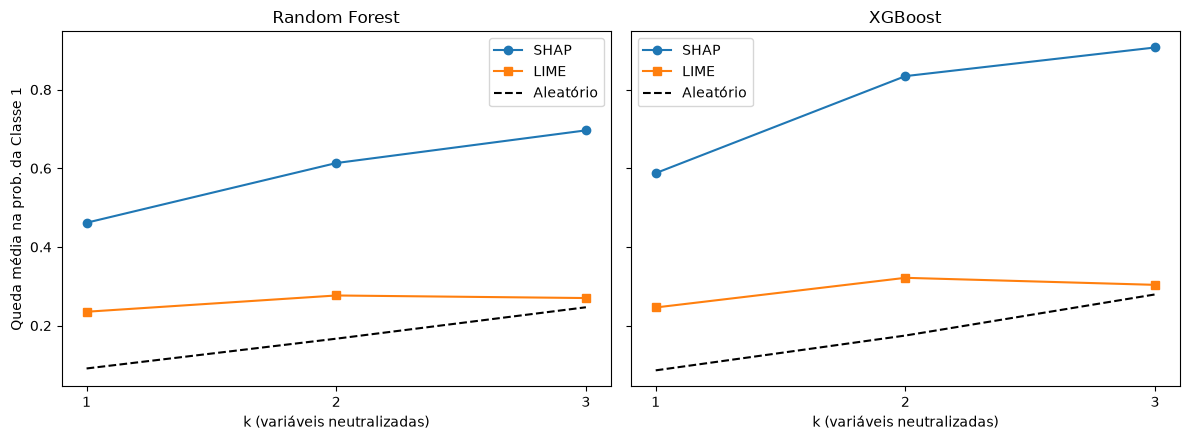

In [3]:
medias = X_train.mean().values
# k limitado a 3: com valores maiores passam a ser neutralizadas variáveis que empurravam
# a predição para a Classe 0, o que mascara o efeito das variáveis realmente relevantes
KS = [1, 2, 3]
N_SORTEIOS = 20
rng = np.random.default_rng(SEED)
n, p = X_amostra.shape
base = X_amostra.values

linhas = []
for nome, modelo in modelos.items():
    p0 = modelo.predict_proba(pd.DataFrame(base, columns=colunas))[:, 1]

    def queda(escolhas):
        Xm = base.copy()
        Xm[np.arange(n)[:, None], escolhas] = medias[escolhas]
        p1 = modelo.predict_proba(pd.DataFrame(Xm, columns=colunas))[:, 1]
        return (p0 - p1).mean()

    # Controle: neutralizar k variáveis sorteadas ao acaso (média de vários sorteios)
    aleatoria = {
        k: np.mean([queda(np.argsort(rng.random((n, p)), axis=1)[:, :k]) for _ in range(N_SORTEIOS)])
        for k in KS
    }

    for metodo in ["SHAP", "LIME"]:
        A = atribuicoes[(nome, metodo)]
        ordem = np.argsort(-A, axis=1)  # da que mais empurrou para a Classe 1 à que menos
        for k in KS:
            q = queda(ordem[:, :k])
            linhas.append(
                {
                    "Modelo": nome,
                    "Método": metodo,
                    "k": k,
                    "Queda (explicação)": q,
                    "Queda (aleatório)": aleatoria[k],
                    "Ganho": q - aleatoria[k],
                }
            )

tab_ablacao = pd.DataFrame(linhas)
tab_ablacao.round(4).to_csv("../resultados/fidelidade_ablacao.csv", index=False)
print(tab_ablacao.round(4).to_string(index=False))

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, nome in zip(eixos, modelos):
    sub = tab_ablacao[tab_ablacao["Modelo"] == nome]
    for metodo, estilo in [("SHAP", "o-"), ("LIME", "s-")]:
        s = sub[sub["Método"] == metodo]
        ax.plot(s["k"], s["Queda (explicação)"], estilo, label=metodo)
    ref = sub[sub["Método"] == "SHAP"]
    ax.plot(ref["k"], ref["Queda (aleatório)"], "k--", label="Aleatório")
    ax.set_title(nome)
    ax.set_xlabel("k (variáveis neutralizadas)")
    ax.set_xticks(KS)
    ax.legend()
eixos[0].set_ylabel("Queda média na prob. da Classe 1")
plt.tight_layout()
plt.savefig("../resultados/fidelidade_ablacao.png", dpi=300)
plt.show()

In [4]:
# %% [CÉLULA 4] Qualidade da aproximação do LIME (R² local) e resumo
r2 = pd.read_csv("../resultados/lime_r2.csv", index_col=0)
print("R² local médio do LIME:")
print(r2.mean().round(3))

print("\n--- Resumo da fidelidade ---")
print(tab_verdade)
print(tab_ablacao[tab_ablacao["k"] == 3].set_index(["Modelo", "Método"])[["Queda (explicação)", "Queda (aleatório)", "Ganho"]].round(4))


R² local médio do LIME:
r2_lime_rf     0.471
r2_lime_xgb    0.316
dtype: float64

--- Resumo da fidelidade ---
                      Importância no ruído (%)  Precisão@7 (%)
Modelo        Método                                          
Random Forest SHAP                        8.72           83.57
              LIME                        2.57           93.29
XGBoost       SHAP                        7.94           83.14
              LIME                        3.96           89.86
                      Queda (explicação)  Queda (aleatório)   Ganho
Modelo        Método                                               
Random Forest SHAP                0.6964             0.2466  0.4498
              LIME                0.2701             0.2466  0.0235
XGBoost       SHAP                0.9071             0.2793  0.6279
              LIME                0.3036             0.2793  0.0244
